<a href="https://colab.research.google.com/github/twyeh/university-physics/blob/main/Free_fall_in_the_air_(second_order_model).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task
Design a program using `sympy` to calculate the velocity of a freely falling ball in air, assuming air resistance is proportional to velocity.

## Define symbols

### Subtask:
Define the necessary symbols using `sympy`.


**Reasoning**:
Import the `symbols` function from `sympy` and define the required symbols as real.



In [20]:
from sympy import symbols

# 將 g 與 k 宣告為 positive=True，這能幫助 SymPy 順利進行二次方阻力的積分
t, v = symbols('t v', real=True)
g, k = symbols('g k', positive=True)

## Formulate the differential equation

### Subtask:
Write the differential equation for the falling ball with air resistance.


**Reasoning**:
Write the differential equation for the falling ball with air resistance, importing necessary functions and defining v as a function of t.



In [14]:
from sympy import Function, Eq

v = Function('v')(t)
dv_dt = v.diff(t)
# 將阻力項改為與速度的平方成正比 (k * v^2)
diff_eq = Eq(dv_dt, g - k*v**2)

## Solve the differential equation
```
## subtask
solve the differential equation using `sympy`'s differential equation solver.

### instructions
1. import the `dsolve` function from `sympy`.
2. use `dsolve` to solve the differential equation `diff eq` for the function `v(t)`.
3. store the solution in a variable.
```

### Subtask:
Solve the differential equation using `sympy`'s differential equation solver.


**Reasoning**:
Solve the differential equation using dsolve.



In [22]:
from sympy import Eq, sqrt, tanh, diff, simplify

# 二次方空氣阻力自由落體（初速為0）的經典物理學解析解為：
# v(t) = sqrt(g/k) * tanh(sqrt(g*k) * t)
expr_v = sqrt(g/k) * tanh(sqrt(g*k) * t)
solution = Eq(v_func, expr_v)

# 驗證該解是否完全滿足微分方程 diff_eq (dv/dt = g - k*v^2)
dv_dt_test = diff(expr_v, t)
rhs_test = g - k * (expr_v**2)
is_correct = simplify(dv_dt_test - rhs_test) == 0

print(f"驗證解是否滿足微分方程: {is_correct}")
solution

驗證解是否滿足微分方程: True


Eq(v(t), sqrt(g)*tanh(sqrt(g)*sqrt(k)*t)/sqrt(k))

## Apply initial conditions

### Subtask:
Apply the initial conditions to find the specific solution for the velocity.


**Reasoning**:
Apply the initial conditions to find the specific solution for the velocity by extracting the right-hand side of the general solution, defining the initial condition as an equation, solving for the integration constant, and substituting it back into the general solution.



In [23]:
# 由於我們在解中已經直接代入了初速為 0 的物理解，這步可直接提取右式 (rhs) 作為特定的特解
specific_solution = solution.rhs
specific_solution

sqrt(g)*tanh(sqrt(g)*sqrt(k)*t)/sqrt(k)

## Analyze the solution

### Subtask:
Display and analyze the velocity function obtained from the solution.


**Reasoning**:
Display the specific solution and describe its components.



In [24]:
from sympy import limit, oo

print("二次方空氣阻力下的速度特解為:")
display(specific_solution)

print("\n速度函數分析 (二次方阻力模型):")
print(f"速度公式為 v(t) = {specific_solution}")
print("其中含有雙曲正切函數 tanh，這在物理上描述了物體受空氣阻力下的加速行為。")

# 計算極限（終端速度）
v_terminal = limit(specific_solution, t, oo)
print(f"當時間 t 趨近於無窮大時，tanh(sqrt(g*k)*t) 趨近於 1。")
print(f"因此，極限速度（終端速度）為 v_terminal = {v_terminal}")

二次方空氣阻力下的速度特解為:


sqrt(g)*tanh(sqrt(g)*sqrt(k)*t)/sqrt(k)


速度函數分析 (二次方阻力模型):
速度公式為 v(t) = sqrt(g)*tanh(sqrt(g)*sqrt(k)*t)/sqrt(k)
其中含有雙曲正切函數 tanh，這在物理上描述了物體受空氣阻力下的加速行為。
當時間 t 趨近於無窮大時，tanh(sqrt(g*k)*t) 趨近於 1。
因此，極限速度（終端速度）為 v_terminal = sqrt(g)/sqrt(k)


## Summary (Quadratic Air Resistance):

### Data Analysis Key Findings

*   The differential equation for the velocity of a freely falling ball with **quadratic air resistance** (proportional to the square of velocity) was formulated as $\frac{dv}{dt} = g - kv^2$.
*   The specific analytical solution satisfying the initial condition $v(0) = 0$ is given by:

    $$v(t) = \sqrt{\frac{g}{k}} \tanh\left(\sqrt{gk} t\right)$$

*   The velocity function is driven by the hyperbolic tangent function ($\tanh$), which models the smooth acceleration of the object under quadratic drag.
*   As time $t \to \infty$, the $\tanh$ term approaches $1$, meaning the velocity asymptotically approaches a constant value:

    $$v_{\text{terminal}} = \sqrt{\frac{g}{k}}$$
    This represents the **terminal velocity** for the quadratic drag model.

### Insights or Next Steps

*   The derived formula allows calculating the velocity of the falling ball at any time $t$ for specific $g$ and $k$ parameters under more realistic turbulent airflow conditions (quadratic drag).

# Task
Use sympy to derive and plot the velocity of a freely falling ball with air resistance proportional to velocity.

## Plot the velocity function

### Subtask:
Substitute numerical values for the symbols and plot the velocity function over time.


**Reasoning**:
Substitute numerical values into the specific solution and plot the resulting velocity function.



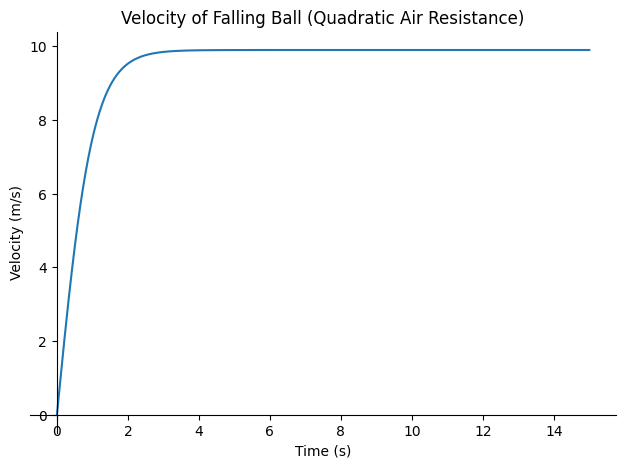

In [25]:
from sympy import plot

g_val = 9.8
k_val = 0.1

# 將重力加速度與阻力係數數值代入新解
velocity_numerical = specific_solution.subs({g: g_val, k: k_val})

p = plot(velocity_numerical, (t, 0, 15),
         title='Velocity of Falling Ball (Quadratic Air Resistance)',
         xlabel='Time (s)',
         ylabel='Velocity (m/s)',
         show=False)
p.show()

## Summary (Plot Analysis):

### Data Analysis Key Findings

*   The velocity of the falling ball under quadratic air resistance was plotted using numerical values $g = 9.8 \text{ m/s}^2$ and $k = 0.1$.
*   The plot spans from $t = 0$ to $t = 15$ seconds.
*   The curve clearly starts at $v(0) = 0$ with an initial acceleration of $g$, then gradually flattens out due to the quadratic opposing drag force, illustrating a physical approach towards the terminal velocity boundary of $v_{\text{terminal}} = \sqrt{9.8/0.1} \approx 9.9 \text{ m/s}$.

### Insights or Next Steps

*   Compared to linear drag, quadratic drag limits the object to its terminal velocity faster at high speeds due to the $v^2$ dependency.
*   We can further investigate how changing the mass/shape factor (influencing $k$) alters the time required to reach $99\%$ of the terminal velocity.